# Uniform Cost Search

**Group Members:**
- 191630 Munene Michelle Gakenyi
- 177480 Miheso Aoi Mmitsi
- 190431 Ochieng Wendy Wendo

### Reference Weighted Directed Graph

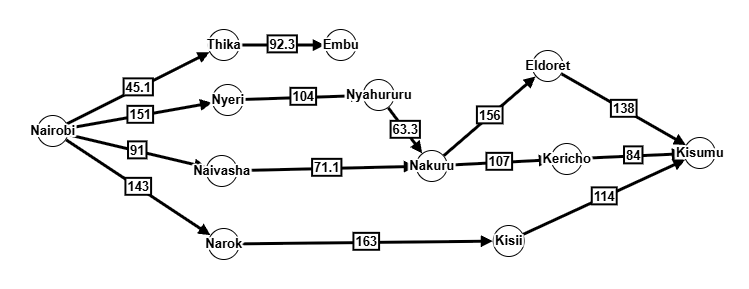

This notebook implements UCS in 2 ways:
1. Using a priority queue (min-heap)
2. Using a sorted list and recursion

Both implementations use the same weighted directed graph so that their results can be compared.

## WeightedDirected Graph

In [20]:
class WeightedDirectedGraph:
    def __init__(self):
        self.adj_list = {}

    def add_node(self, node):
        if node not in self.adj_list:
            self.adj_list[node] = {}
            
    def add_edge(self, from_node, to_node, weight):
        # Ensure both nodes exist in the graph first
        self.add_node(from_node) 
        self.add_node(to_node)

        # Add the directed link
        self.adj_list[from_node][to_node] = weight

    def get_weight(self, from_node, to_node):
        return self.adj_list.get(from_node, {}).get(to_node, None)

    def remove_edge(self, from_node, to_node):
        if from_node in self.adj_list and to_node in self.adj_list[from_node]:
            del self.adj_list[from_node][to_node]

    def get_neighbours(self, node):
        if node in self.adj_list:
            return list(self.adj_list[node].items())

        return []

    def __str__(self):
        result = []

        for node, neighbors in self.adj_list.items():
            edges = [f"{neighbor}(w:{weight})" for neighbor, weight in neighbors.items()]

            result.append(f"{node} -> {edges}")

        return "\n".join(result)

In [21]:
graph = WeightedDirectedGraph()

**Populate the graph**

In [22]:
graph.add_edge("Nairobi", "Thika", 45.1)
graph.add_edge("Thika", "Embu", 92.3)

graph.add_edge("Nairobi", "Nyeri", 151)
graph.add_edge("Nyeri", "Nyahururu", 104)
graph.add_edge("Nyahururu", "Nakuru", 63.3)

graph.add_edge("Nairobi", "Naivasha", 91)
graph.add_edge("Naivasha", "Nakuru", 71.1)

graph.add_edge("Nakuru", "Eldoret", 156)
graph.add_edge("Eldoret", "Kisumu", 138)
graph.add_edge("Nakuru", "Kericho", 107)
graph.add_edge("Kericho", "Kisumu", 84)

graph.add_edge("Nairobi", "Narok", 143)
graph.add_edge("Narok", "Kisii", 163)
graph.add_edge("Kisii", "Kisumu", 114)

In [23]:
print(graph)

Nairobi -> ['Thika(w:45.1)', 'Nyeri(w:151)', 'Naivasha(w:91)', 'Narok(w:143)']
Thika -> ['Embu(w:92.3)']
Embu -> []
Nyeri -> ['Nyahururu(w:104)']
Nyahururu -> ['Nakuru(w:63.3)']
Nakuru -> ['Eldoret(w:156)', 'Kericho(w:107)']
Naivasha -> ['Nakuru(w:71.1)']
Eldoret -> ['Kisumu(w:138)']
Kisumu -> []
Kericho -> ['Kisumu(w:84)']
Narok -> ['Kisii(w:163)']
Kisii -> ['Kisumu(w:114)']


## Method 1 - Using a Priority Queue

In [24]:
import heapq # implemens a min-heap

A min-heap ensures that the smallest-item is always accessible at index 0.

For our UCS implementation, that means the path with the lowest cumulative cost is always selected first.

In [25]:
def UniformCostSearch(start_node, to_node):
    priority_queue = []

    # Add starting node
    heapq.heappush(priority_queue, (0, start_node, [start_node])) # (cost, current_node, path)

    best_cost = {start_node: 0} # helps avoid exploring unnecessarily expensive routes to nodes we've already reached more cheaply

    # Continue while there are paths to explore
    while priority_queue:

        # Get path with lowest cumulative cost
        cost, current_node, path = heapq.heappop(priority_queue)

        print(f"Exploring: {path} Cost: {cost}")

        # Ignore paths that are no longer optimal
        if cost > best_cost[current_node]:
            continue

        # Check if goal has been reached
        if current_node == to_node:
            print("Optimal path: ", "->".join(path))
            print("Total cost: ", cost)
            return path, cost

        # Expand current node's neigbours
        for neighbour, weight in graph.get_neighbours(current_node):
            new_cost = cost + weight

            if neighbour not in best_cost or new_cost < best_cost[neighbour]:
                best_cost[neighbour] = new_cost

                new_path = path + [neighbour]

                heapq.heappush(
                    priority_queue,
                    (new_cost, neighbour, new_path)
                )

    print(f"No path found from {start_node} to {to_node}")
    return None
        

In [26]:
UniformCostSearch("Nairobi", "Kisumu")

Exploring: ['Nairobi'] Cost: 0
Exploring: ['Nairobi', 'Thika'] Cost: 45.1
Exploring: ['Nairobi', 'Naivasha'] Cost: 91
Exploring: ['Nairobi', 'Thika', 'Embu'] Cost: 137.4
Exploring: ['Nairobi', 'Narok'] Cost: 143
Exploring: ['Nairobi', 'Nyeri'] Cost: 151
Exploring: ['Nairobi', 'Naivasha', 'Nakuru'] Cost: 162.1
Exploring: ['Nairobi', 'Nyeri', 'Nyahururu'] Cost: 255
Exploring: ['Nairobi', 'Naivasha', 'Nakuru', 'Kericho'] Cost: 269.1
Exploring: ['Nairobi', 'Narok', 'Kisii'] Cost: 306
Exploring: ['Nairobi', 'Naivasha', 'Nakuru', 'Eldoret'] Cost: 318.1
Exploring: ['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu'] Cost: 353.1
Optimal path:  Nairobi->Naivasha->Nakuru->Kericho->Kisumu
Total cost:  353.1


(['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu'], 353.1)

## Method 2 - Using a Sorted List and Recursion

In [27]:
paths = []

def UniformCostSearch(from_node, to_node, cost=0):
    
    current_from = from_node.split("-")[-1]

    current_path = {f"{from_node}": cost}

    neighbours = graph.get_neighbours(current_from)

    # Arrange neighbours in ascending order
    neighbours.sort(key=lambda x: x[1])

    for neighbour in neighbours:
         # Add new paths to paths list
        new_path = f"{next(iter(current_path))}-{neighbour[0]}"
    
        paths.append({f"{new_path}": cost + neighbour[1]})

    # Arrange paths in ascending order
    paths.sort(key=lambda x: next(iter(x.values())))

    print("Paths: ")

    for path in paths:
        print(path)

    print()
    
    # Go through paths and remove complete & ended
    to_be_removed = []
    
    for path in paths:
        last_path = next(iter(path)).split("-")[-1]

        if not graph.get_neighbours(last_path) and last_path != to_node:
            print("Path has no more neighbours: ", path)
            
            to_be_removed.append(path)

    for x in to_be_removed:
        paths.remove(x)

    if len(paths) == 0 and cost != 0:
        print(f"No path is able to lead to the {to_node}!")
        
        return

    # Pop path with lowest cumulative cost, g
    lowest_path = paths.pop(0)

    print("Lowest path: ", lowest_path)

    print()

    new_from_node = next(iter(lowest_path))
    new_cost = next(iter(lowest_path.values()))

    last_node = new_from_node.split("-")[-1]

    if last_node == to_node:
        print("Optimal path:", lowest_path)
        return

    UniformCostSearch(
        new_from_node, 
        to_node,
        new_cost
    )
        

In [28]:
UniformCostSearch("Nairobi", "Kisumu")

Paths: 
{'Nairobi-Thika': 45.1}
{'Nairobi-Naivasha': 91}
{'Nairobi-Narok': 143}
{'Nairobi-Nyeri': 151}

Lowest path:  {'Nairobi-Thika': 45.1}

Paths: 
{'Nairobi-Naivasha': 91}
{'Nairobi-Thika-Embu': 137.4}
{'Nairobi-Narok': 143}
{'Nairobi-Nyeri': 151}

Path has no more neighbours:  {'Nairobi-Thika-Embu': 137.4}
Lowest path:  {'Nairobi-Naivasha': 91}

Paths: 
{'Nairobi-Narok': 143}
{'Nairobi-Nyeri': 151}
{'Nairobi-Naivasha-Nakuru': 162.1}

Lowest path:  {'Nairobi-Narok': 143}

Paths: 
{'Nairobi-Nyeri': 151}
{'Nairobi-Naivasha-Nakuru': 162.1}
{'Nairobi-Narok-Kisii': 306}

Lowest path:  {'Nairobi-Nyeri': 151}

Paths: 
{'Nairobi-Naivasha-Nakuru': 162.1}
{'Nairobi-Nyeri-Nyahururu': 255}
{'Nairobi-Narok-Kisii': 306}

Lowest path:  {'Nairobi-Naivasha-Nakuru': 162.1}

Paths: 
{'Nairobi-Nyeri-Nyahururu': 255}
{'Nairobi-Naivasha-Nakuru-Kericho': 269.1}
{'Nairobi-Narok-Kisii': 306}
{'Nairobi-Naivasha-Nakuru-Eldoret': 318.1}

Lowest path:  {'Nairobi-Nyeri-Nyahururu': 255}

Paths: 
{'Nairobi-Naivas

**Limitations:**
- Cannot detect cycles in weighted directed graph

## Conclusion

For the Nairobi-to-Kisumu example, both implementations find the optimal route:

**Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu**

The total path cost is **353.1**

## Cool Team Photo

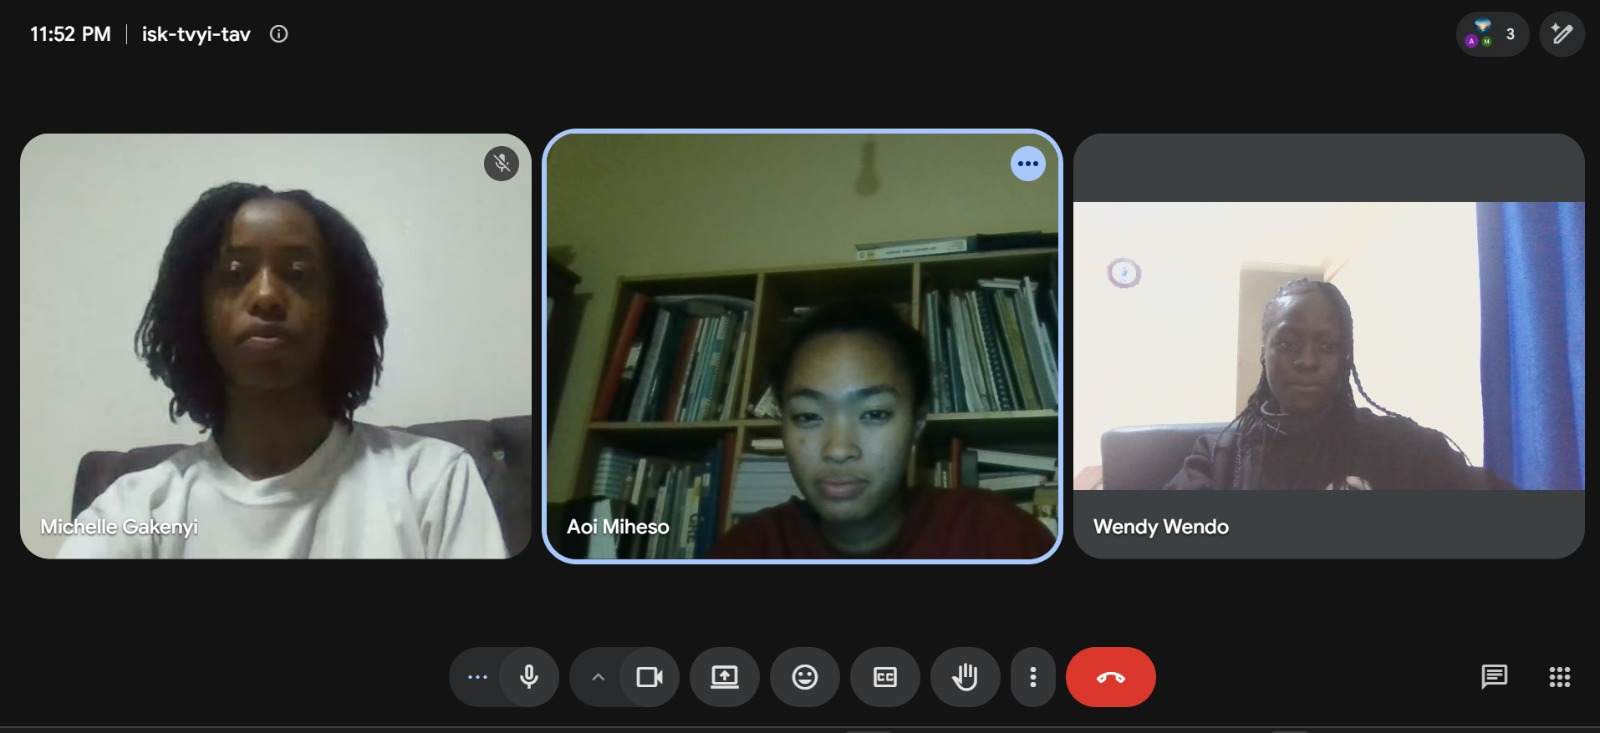